# Bitcoin Market Intelligence, part 2: causal inference, regimes, forecasting and statistical rigor

Part 1 (`btc_market_analysis.ipynb`) described *what happened*. This notebook asks the harder questions a senior analyst gets:

| # | Question | Method | Decision it feeds |
|---|---|---|---|
| A1 | Did the **Jan-2024 US spot-ETF launch** change how Bitcoin trades? | Interrupted time series (HAC errors), Quandt–Andrews break scan, in-time placebo tests | Whether to reset risk and product assumptions for an "ETF era" |
| A2 | Which **volatility regime** are we in, and can we forecast risk? | 3-state Markov-switching model; GARCH(1,1) with Student-t errors (custom MLE); Kupiec VaR backtest | Dynamic risk limits and stress alerts |
| A3 | Can we forecast **next week's hourly volume** for staffing? | Rolling-origin backtest of seasonal baselines vs gradient boosting (91 weeks) | Support rota and capacity planning |
| A4 | Which part-1 findings are **statistically real**, and what should a customer expect? | Permutation tests, bootstrap CIs, Benjamini–Hochberg FDR control; stationary-block-bootstrap Monte Carlo | Which claims can go in front of customers |

All code lives in `src/advanced.py`, and charts are in `src/charts_advanced.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import analysis as A, advanced as X, charts_advanced as CA
pd.set_option("display.float_format", "{:,.4f}".format)
daily, hourly = A.load_daily(), A.load_hourly()

## A1. Did the spot-ETF launch change Bitcoin? (causal inference)

US spot bitcoin ETFs started trading on **11 January 2024**. If ETFs brought in US institutional money, we'd expect: (1) lower volatility, (2) more trading during US market hours, and (3) relatively less weekend trading, since ETFs don't trade on weekends.

**Design.** Weekly metrics, two years before vs after the launch.
- *Mean difference* with Newey–West (HAC) errors, because weekly metrics are autocorrelated and ordinary p-values would be too optimistic.
- *Interrupted time series* (level + slope change against the extrapolated pre-trend).
- *Break scan*: compute the Chow F-statistic at every candidate week. If the ETF caused the change, the biggest break should sit near January 2024.
- *Placebo test*: re-run the ITS at 40 fake event dates. The real effect should be unusual compared with these.

In [2]:
weekly, etf_table, etf_details = X.etf_impact(daily, hourly)
etf_table[["pre_mean", "post_mean", "mean_diff_p", "level_shift", "hac_p_value", "placebo_p_value", "strongest_break_week"]]

,pre_mean,post_mean,mean_diff_p,level_shift,hac_p_value,placebo_p_value,strongest_break_week
metric,,,,,,,
Realized volatility (ann.),0.4910,0.4363,0.2759,0.2480,0.0000,0.1750,2022-08-07
Weekend share of weekly volume,0.1511,0.1476,0.6602,0.0030,0.8396,0.8000,2024-12-15
US-session share of weekday volume,0.4170,0.4584,0.0017,0.0432,0.1169,0.0250,2024-10-06


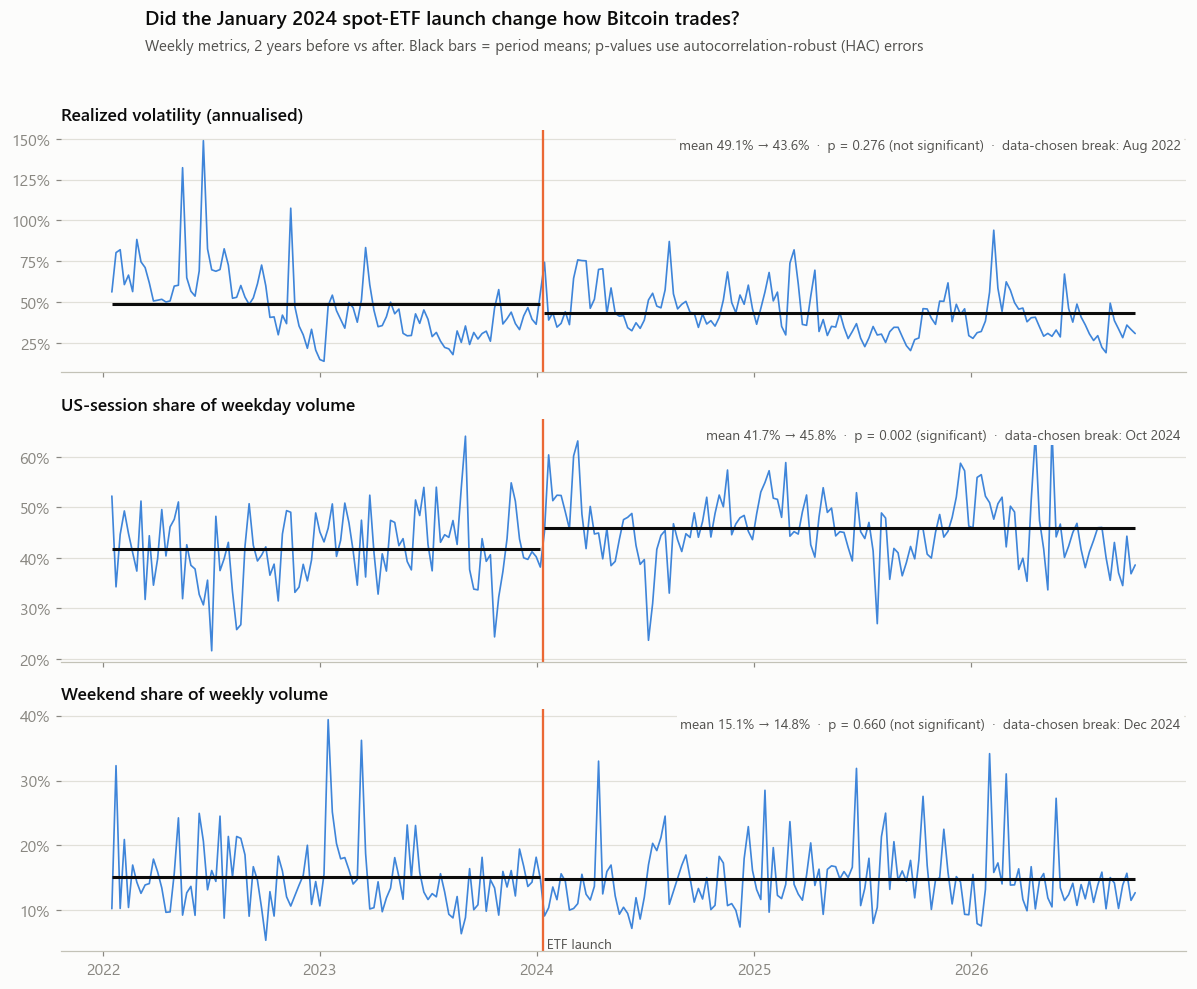

In [3]:
CA.etf_its(weekly, etf_table, etf_details);

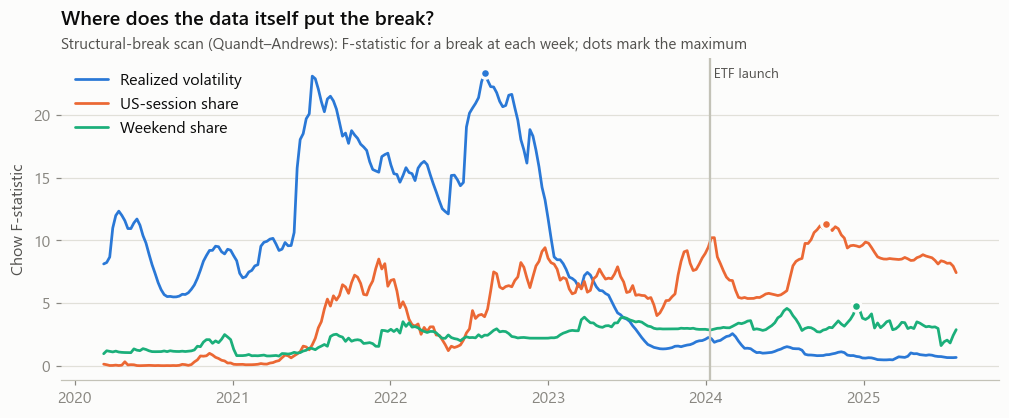

In [4]:
CA.break_scan(etf_details);

**Findings**
- **Volatility: the ETF did *not* cause the decline.** The mean fell from 49% to 44%, but that's not significant (p = 0.28). The data puts the break in **August 2022**, after the Luna/3AC/FTX deleveraging, 17 months *before* the ETF. The ITS level shift comes out *positive*, because extrapolating 2022's falling trend predicts impossibly low volatility. That's a textbook reason not to trust a single ITS specification.
- **US-session share: a real shift, but it builds slowly.** The share of weekday volume traded 14:00–21:00 UTC rose from **41.7% to 45.8%** (HAC p = 0.002, placebo p = 0.025). The strongest break is **October 2024**, so the change built up over the ETF's first year rather than appearing on launch day. That fits gradual ETF adoption, but it's also consistent with other US-driven flows in 2024.
- **Weekend share: no change** (15.1% → 14.8%, p = 0.66).
- **Caveats:** this is one exchange's volume (Bitstamp; ETF trades themselves don't appear here). The April 2024 halving and macro conditions fall in the same window, and with no untreated control market this is evidence, not proof.

**Decision:** don't justify lower risk limits with "ETFs made Bitcoin safer". The volatility decline is real (see A4) but started earlier. Do move ops and marketing toward US hours, where the share of activity is rising.

## A2. Volatility regimes and risk forecasting

### Markov-switching regimes
A 3-state model where each regime has its own mean and variance, and the market moves between regimes according to a transition matrix estimated from the data.

In [5]:
regimes, regime_summary, transitions = X.markov_regimes(daily)
regime_summary

,share_of_days,daily_vol_pct,ann_vol,mean_daily_return_pct,expected_duration_days,observed_median_run_days,share_of_days_2024plus
regime,,,,,,,
Calm,0.3810,1.0668,0.2038,0.0184,3.7701,4.0000,0.4960
Normal,0.4457,3.2198,0.6152,0.2957,4.2726,4.0000,0.4772
Stress,0.1733,6.4728,1.2366,-0.2120,12.5828,10.0000,0.0267


In [6]:
transitions

,to Calm,to Normal,to Stress
from Calm,0.7348,0.2593,0.0060
from Normal,0.2075,0.7660,0.0265
from Stress,0.0002,0.0793,0.9205


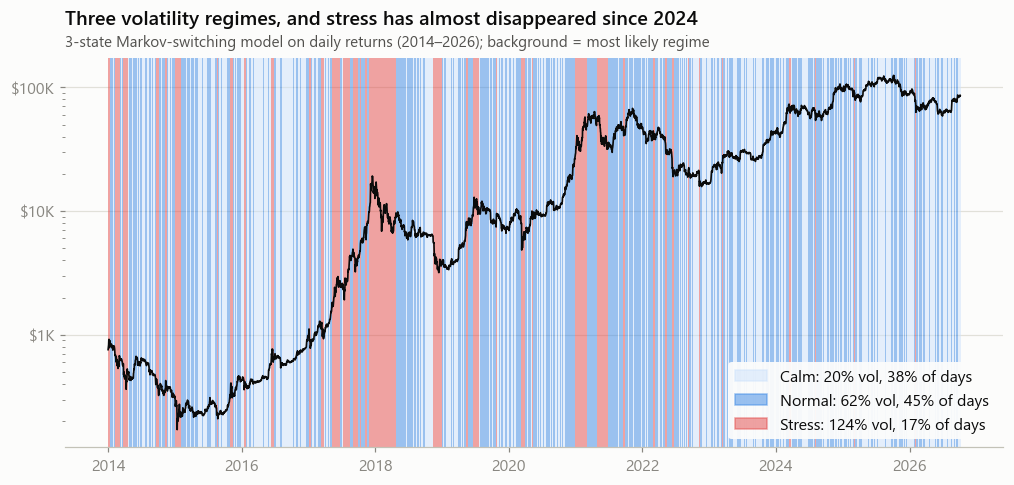

In [7]:
CA.regimes(regimes, regime_summary);

In [8]:
current = regimes.iloc[-1]
print(f"Latest day ({regimes.index[-1]:%Y-%m-%d}): {current['regime']}  "
      f"(P calm={current['Calm']:.2f}, normal={current['Normal']:.2f}, stress={current['Stress']:.2f})")
regimes["regime"].groupby(regimes.index.year).value_counts(normalize=True).unstack().fillna(0).round(2)

Latest day (2026-10-06): Calm  (P calm=0.79, normal=0.20, stress=0.00)


regime,Calm,Normal,Stress
datetime,,,
2014,0.2900,0.4800,0.2200
2015,0.4200,0.4300,0.1500
2016,0.6800,0.2400,0.0800
2017,0.1200,0.3900,0.5000
2018,0.2400,0.3200,0.4500
2019,0.3900,0.4700,0.1400
2020,0.3200,0.5800,0.1000
2021,0.0800,0.5600,0.3600
2022,0.3400,0.5300,0.1300


**Findings**
- **Calm** (20% annualised vol), **Normal** (62%) and **Stress** (124%). Stress is the only regime with a negative average return.
- **Stress is persistent**: once in it, there's a 92% chance of staying the next day, an expected duration of about 13 days. Calm and Normal switch every 4 days or so.
- **Stress has nearly vanished**: 17% of days over 2014–26 but **2.7% of days since 2024**. The market now spends about half its time in Calm.

### GARCH(1,1) with Student-t errors: out-of-sample volatility forecasts

In [9]:
fc, vol_scores, garch_params = X.volatility_forecast_backtest(daily)
pd.DataFrame(garch_params).T[["alpha", "beta", "persistence", "nu"]]

,alpha,beta,persistence,nu
2020,0.1287,0.8713,1.0000,3.3053
2021,0.1670,0.8330,1.0000,3.1635
2022,0.1078,0.8922,1.0000,3.3856
2023,0.1260,0.8740,1.0000,3.3044
2024,0.1038,0.8962,1.0000,3.2282
2025,0.1044,0.8956,1.0000,3.2308
2026,0.1040,0.8960,1.0000,3.2336


In [10]:
vol_scores

,RMSE_vol_pct,QLIKE,corr_with_realized
model,,,
"GARCH(1,1)-t",1.3507,0.3173,0.6858
EWMA (RiskMetrics),1.3861,0.3459,0.6488
30-day historical,1.5467,0.4279,0.5541


In [11]:
nu = garch_params[max(garch_params)]["nu"]
bt = pd.DataFrame([{k: v for k, v in X.var_backtest(fc, m, lvl, nu=nu if "GARCH" in m else None).items() if k != "var_series"}
                   for lvl in (0.95, 0.99) for m in ["GARCH(1,1)-t", "EWMA (RiskMetrics)", "30-day historical"]])
bt[["model", "level", "days", "expected_breaches", "breaches", "breach_rate", "kupiec_p"]]

,model,level,days,expected_breaches,breaches,breach_rate,kupiec_p
0,"GARCH(1,1)-t",0.9500,2471,123.5500,126,0.0510,0.8216
1,EWMA (RiskMetrics),0.9500,2471,123.5500,121,0.0490,0.8133
2,30-day historical,0.9500,2471,123.5500,124,0.0502,0.9669
3,"GARCH(1,1)-t",0.9900,2471,24.7100,25,0.0101,0.9533
4,EWMA (RiskMetrics),0.9900,2471,24.7100,51,0.0206,0.0000
5,30-day historical,0.9900,2471,24.7100,58,0.0235,0.0000


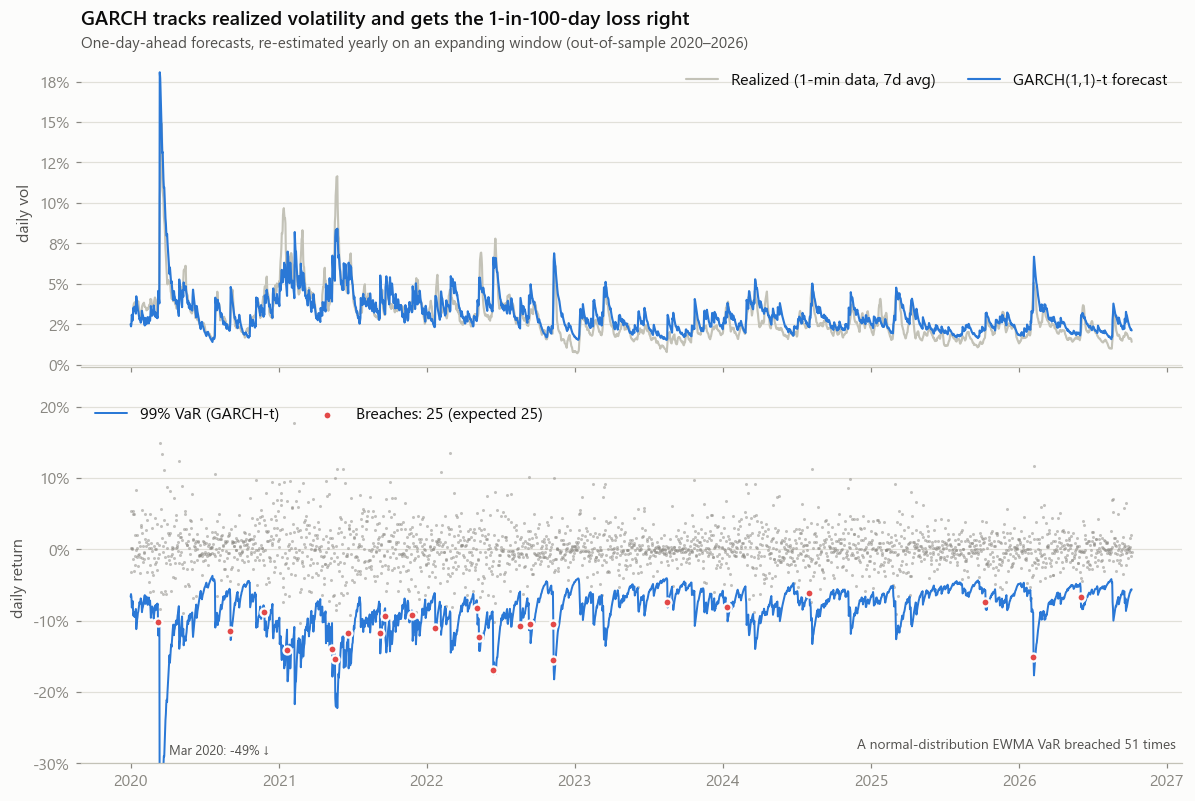

In [12]:
vb = X.var_backtest(fc, "GARCH(1,1)-t", 0.99, nu=nu)
vb_norm = X.var_backtest(fc, "EWMA (RiskMetrics)", 0.99)
CA.garch_var(fc, vb["var_series"], vb["breaches"], vb["expected_breaches"], vb_norm["breaches"]);

**Findings**
- Forecasts are scored against **realized volatility computed from 1-minute returns**, a much cleaner target than squared daily returns. That's possible only because we have minute data.
- **GARCH-t beats the industry-standard EWMA (RiskMetrics) and 30-day historical volatility** on both QLIKE (the robust loss for variance forecasts) and RMSE.
- **Tails are what matter.** At 99%, GARCH-t breached **25 times against 24.7 expected** (Kupiec p ≈ 0.95, well calibrated). The normal-distribution EWMA breached **51 times**, double the promised rate (p < 0.001). Fitted tail thickness ν ≈ 3.2 means Bitcoin's daily returns are far fatter-tailed than a normal distribution.
- Persistence α + β ≈ 1.0 (integrated GARCH): volatility shocks never fully decay within the sample. That's a fingerprint of the structural shift seen in A1, and a reason to re-estimate regularly rather than trust a long-run average.

**Decision:** compute margin and collateral VaR with **fat-tailed (Student-t) GARCH**, not normal-distribution EWMA. Add a "stress regime" alert when the Markov stress probability goes above 50%, so risk and support can prepare.

## A3. Forecasting next week's hourly volume (ops planning)

Every Monday 00:00 UTC, forecast all 168 hours of the coming week. Every feature is at least 168 hours old, so there's no look-ahead. The backtest runs over **91 weeks (2025–2026)**, with the boosting model refit every 4 weeks.

In [13]:
preds, fcast_scores = X.volume_forecast_backtest(hourly)
fcast_scores

,WAPE,daily_WAPE,median_APE,bias,top20_hours_hit_rate,skill_vs_naive
model,,,,,,
Seasonal naive (last week),0.7671,0.4381,0.6020,-0.0013,0.3456,0.0000
4-week seasonal mean,0.5984,0.3786,0.5259,-0.1889,0.4626,0.2199
"4-week mean, bias-corrected",0.6538,0.4021,0.5731,0.0168,0.4626,0.1477
Gradient boosting,0.6424,0.4192,0.5865,0.0011,0.4780,0.1625


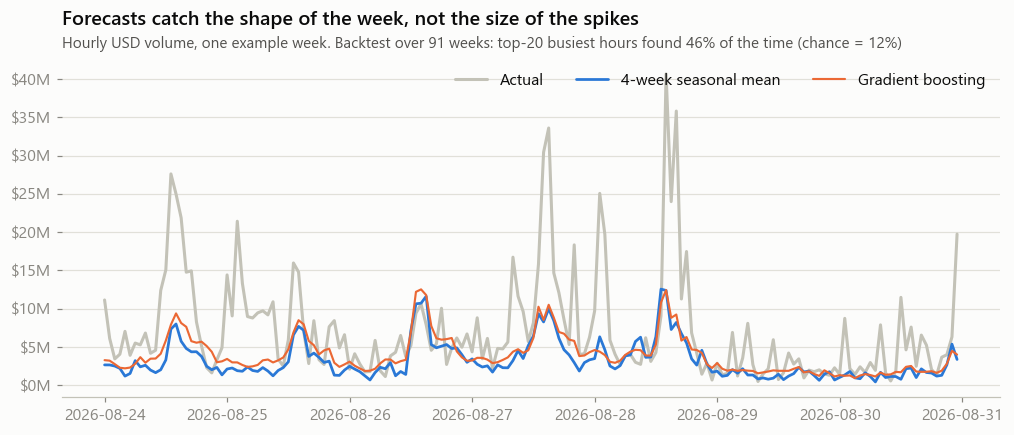

In [14]:
CA.volume_week(preds, fcast_scores);

**Findings**
- Using the last 4 weeks' average for the same hour **cuts hourly error by 22%** compared with "same hour last week". It also finds **46% of next week's 20 busiest hours**, versus 12% by chance.
- **Gradient boosting doesn't beat the 4-week seasonal mean.** The level of volume is driven by news and price shocks, so it isn't predictable a week ahead. The *shape* of the week is predictable, and a simple average already captures it.
- **Metric choice matters.** WAPE rewards *under*-forecasting when volume is spiky, because the median is below the mean. The raw 4-week mean "wins" on WAPE while under-forecasting total volume by 19%. For staffing, under-forecasting is the costlier error, so use the **bias-corrected** version and judge models by the cost of each type of error, not by one accuracy number.

**Decision:** ship the **bias-corrected 4-week seasonal profile** as the staffing forecast. It's transparent, cheap, and as good as ML. Size an on-call buffer for the daily error (about ±40%) instead of chasing more model accuracy.

## A4. Statistical rigor: which findings are real?

Each claim in part 1 is re-tested with a test that respects how the data is structured (shuffling within weeks, block bootstraps for autocorrelation). Then the **false discovery rate** is controlled with Benjamini–Hochberg, because six tests are run at once.

In [15]:
sig = X.significance_tests(daily, hourly)
sig

,estimate,ci_low,ci_high,n,test,p_value,p_adjusted_BH,significant_5pct
claim,,,,,,,,
Next-day rebound after -10% days,0.0280,0.0054,0.0481,37,permutation (random days),0.0002,0.0007,True
Next-day rebound after -5% days,0.0007,-0.0056,0.0054,127,permutation (random days),0.7427,0.7427,False
Weekday changes recurring-buy price,0.0034,NaN,NaN,665,permutation within week,0.7229,0.7427,False
Weekend volume below weekdays (log),-0.5301,NaN,NaN,404,permutation within week,0.0005,0.0007,True
"Volatility ratio, 2024+ vs 2017-20",0.5709,0.4752,0.6829,1010,stationary bootstrap CI,0.0005,0.0007,True
DCA lifts 10th-pct 12m ROI vs lump,0.2062,0.1195,0.2787,142,cohort bootstrap (overlapping),0.0005,0.0007,True


**Findings**
- **Confirmed:** the rebound after −10% days (+2.8 pp next-day median, 95% CI 0.5–4.8), the weekend volume drop (−53%), volatility at **0.57×** its 2017–20 level (CI 0.48–0.68), and DCA lifting the worst-decile 12-month ROI by **+21 pp** (CI 12–28).
- **Not significant:** the rebound after −5% days (p = 0.74) and *any* weekday effect on recurring-buy prices (p = 0.72). These support the "don't build" decisions in part 1.

### Monte Carlo: what range of outcomes should a recurring-buy customer expect?

Part 1 found that 3–4-year holds were profitable for ~100% of start dates since 2014. But those windows overlap heavily and include Bitcoin's hyper-growth years. To get a forward-looking range, simulate 10,000 four-year paths by **stationary block bootstrap** of daily returns. This resamples month-long blocks so trends and volatility clusters survive. Scenario A uses post-2021 returns (today's market); Scenario B uses 2014+.

In [16]:
mc_recent, fan = X.monte_carlo_plans(daily)                                   # scenario A: 2021+
mc_full, _ = X.monte_carlo_plans(daily, sample_from="2014-01-01")             # scenario B: 2014+
mc_recent

prob_loss  prob_loss_gt_30pct      p5  median     p95  \
year strategy                                                             
1    Weekly plan     0.3707              0.0746 -0.3455  0.1186  1.0614   
     Lump sum        0.3723              0.1779 -0.5507  0.2153  2.2011   
2    Weekly plan     0.3141              0.1081 -0.4190  0.2626  2.1236   
     Lump sum        0.3223              0.1891 -0.6391  0.4880  4.8995   
3    Weekly plan     0.2873              0.1181 -0.4550  0.4269  3.4259   
     Lump sum        0.2909              0.1853 -0.6797  0.7964  8.4455   
4    Weekly plan     0.2619              0.1202 -0.4824  0.6007  5.2190   
     Lump sum        0.2617              0.1780 -0.7045  1.1574 14.0204   

                  expected_shortfall_5pct  
year strategy                              
1    Weekly plan                  -0.4251  
     Lump sum                     -0.6416  
2    Weekly plan                  -0.5135  
     Lump sum                     -0.7326  
3    Weekly plan                  -0.5528  
     Lump sum                     -0.7775  
4    Weekly plan                  -0.5866  
     Lump sum                     -0.8044

In [17]:
pd.DataFrame({"P(loss), 2021+ regime": mc_recent.xs("Weekly plan", level=1)["prob_loss"],
              "P(loss), 2014+ history": mc_full.xs("Weekly plan", level=1)["prob_loss"]})

,"P(loss), 2021+ regime","P(loss), 2014+ history"
year,,
1,0.3707,0.3184
2,0.3141,0.2472
3,0.2873,0.1956
4,0.2619,0.1568


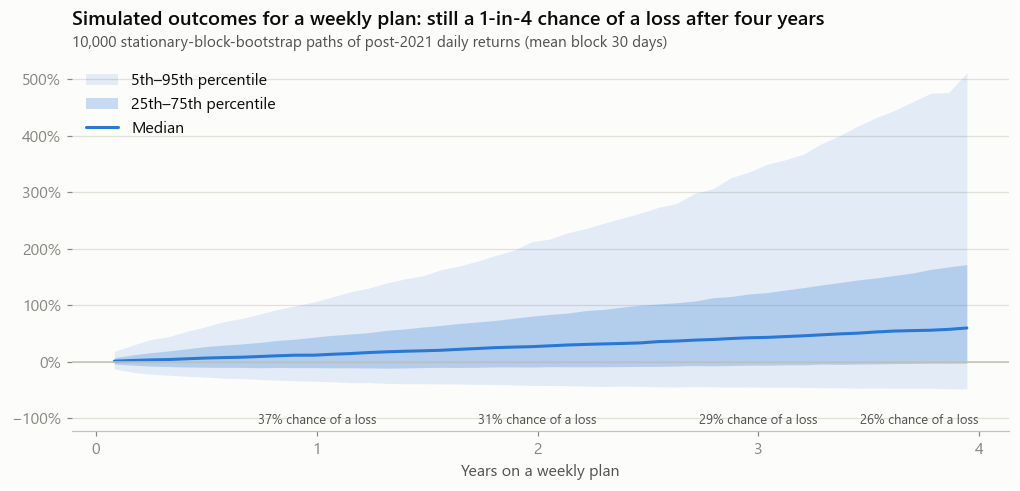

In [18]:
CA.monte_carlo_fan(fan, mc_recent);

**Findings**
- With today's return profile, a weekly plan still has a **~26% chance of being at a loss after four years**. Even resampling the whole 2014+ history gives ~16%. The "≈0% after 3 years" figure from the historical cohorts reflects one exceptional period, not something we can promise.
- Weekly plans and lump sums have similar chances of *some* loss. The difference is **how bad** it gets: in the worst 5% of paths, the 4-year weekly-plan loss averages −59%, versus **−80%** for a lump sum.

**Decision (revises part 1, rec. #3):** don't show historical "99.7% of 3-year holds were profitable" odds in the app. Show a **simulated range of outcomes** (this fan chart) with a plain-language chance of loss. It's more honest, lower compliance risk, and still makes the case for recurring buys through the smaller downside.

## What the advanced layer changed

| Part-1 view | After part 2 |
|---|---|
| "Volatility halved", read as the ETF effect | Volatility halved (CI 0.48–0.68×), but the break is **Aug 2022**, before the ETF. Don't credit the ETF |
| Show historical holding-period odds (99.7%) | Show a **simulated outcome range**: ~26% chance of loss after 4 years in today's regime |
| Static, full-history risk limits | **GARCH-t VaR** (25 vs 25 expected breaches) plus a **stress-regime alert** |
| Staff by historical heatmap | **Bias-corrected 4-week seasonal forecast**. ML adds nothing here |
| Crash cool-down: deprioritised | Confirmed. Effect is significant at −10% (rare), absent at −5% |
| Weekday optimiser: don't build | Confirmed. p = 0.72 |